## Lab 05 · Simple Linear Regression

**Name:** Hasham Munir Qazi

**Roll No:** 2024-SE-32

**Course Code:** CS-3105

**Subject:** Machine Learning Lab

**Lab Instructor:** Engr. Muhammad Awais


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data


T1a: shape of full data = (20484, 11)
T1b: shape of gli = (796, 11)
T1c: summary statistics
          Age  Price_lakh
count  796.00      796.00
mean     6.45       16.59
std      3.11        3.98
min      2.00        6.54
25%      4.00       13.50
50%      6.00       16.50
75%      9.00       19.50
max     15.00       30.00
T1d: correlation(Age, Price_lakh) = -0.896


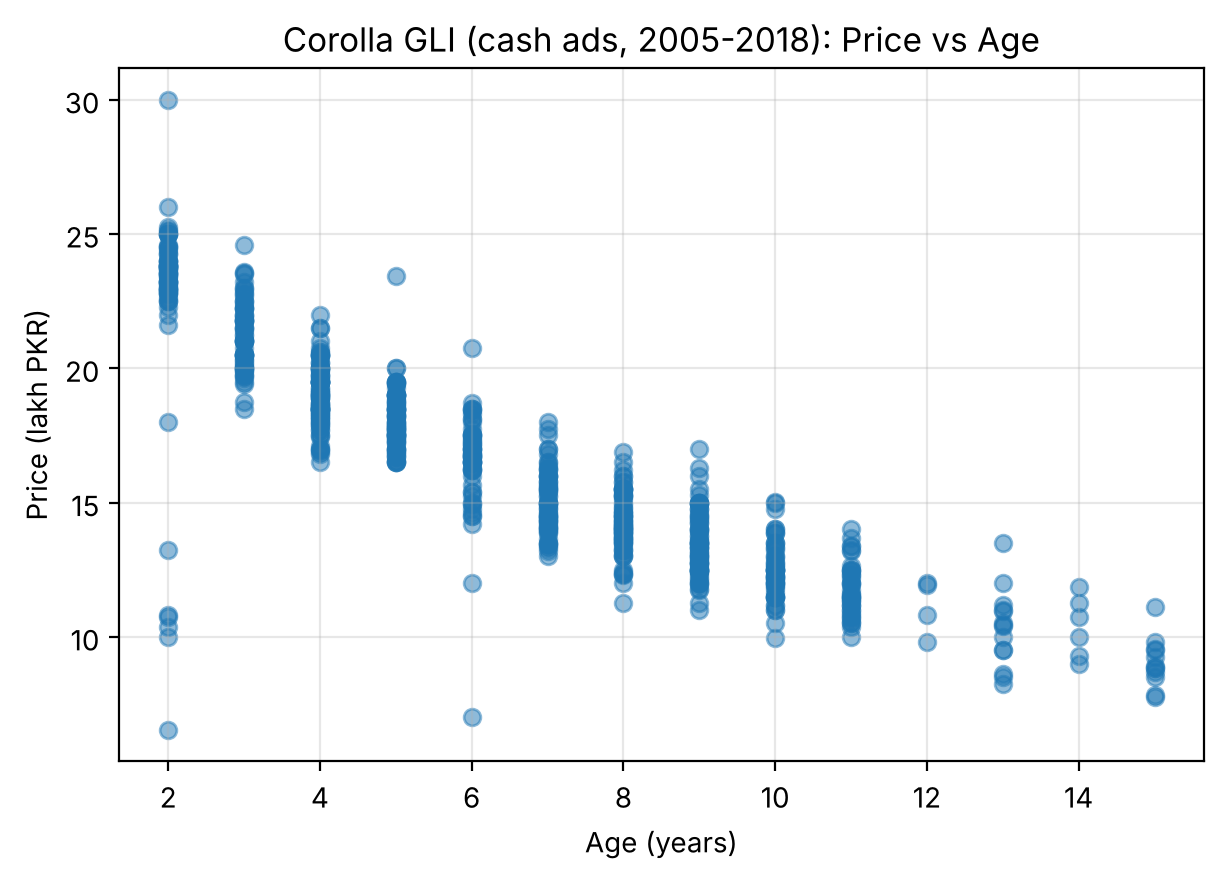

In [2]:
# T1: Load and explore
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a: shape of full data =", df.shape)

# the payment column in this dataset is "Transaction Type" (values: Cash / Installment/Leasing)
pay_col = "Transaction Type"

gli = df[(df["Model"] == "Corolla GLI")
         & (df[pay_col].astype(str).str.strip() == "Cash")
         & (df["Year"].between(2005, 2018))
         & (df["Price_lakh"].between(5, 40))].copy()
print("T1b: shape of gli =", gli.shape)

print("T1c: summary statistics")
print(gli[["Age", "Price_lakh"]].describe().round(2))

corr = gli["Age"].corr(gli["Price_lakh"])
print("T1d: correlation(Age, Price_lakh) =", round(corr, 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.5, color="tab:blue")
plt.title("Corolla GLI (cash ads, 2005-2018): Price vs Age")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()

**Answer:** Yes, a straight line is a sensible model for this data. The correlation between Age and Price_lakh is −0.896, a strong negative linear relationship (r² ≈ 0.80, so about 80 % of the price variation lines up with age). The scatter plot in (e) agrees: price falls steadily as age rises (mean price 16.6 lakh, ages 2–15), and the points form a downward band around a line. The band has clear vertical spread, because cars of the same age differ in condition, mileage and city, and the fall looks slightly steeper for the newest cars than for the oldest, so the line gives a good average trend but not exact prices.

## Task 2 · Features, target and the train/test split


In [3]:
# T2: features, target and split
X = gli[["Age"]]          # double brackets -> 2-D DataFrame (n, 1)
y = gli["Price_lakh"]     # 1-D Series (n,)
print("T2a: X shape =", X.shape, "| y shape =", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("T2b: X_train", X_train.shape, "| X_test", X_test.shape,
      "| y_train", y_train.shape, "| y_test", y_test.shape)

T2a: X shape = (796, 1) | y shape = (796,)
T2b: X_train (636, 1) | X_test (160, 1) | y_train (636,) | y_test (160,)


## Task 3 · Least squares with NumPy (training data only)


In [4]:
# T3: least squares with NumPy, TRAINING data only
x = X_train["Age"].to_numpy()
t = y_train.to_numpy()

x_bar = x.mean()
y_bar = t.mean()
print("T3a: x_bar =", round(x_bar, 4), "| y_bar =", round(y_bar, 4))

b1 = np.sum((x - x_bar) * (t - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print("T3b: slope b1 =", round(b1, 4), "lakh/year | intercept b0 =", round(b0, 4), "lakh")

T3a: x_bar = 6.3821 | y_bar = 16.6533
T3b: slope b1 = -1.146 lakh/year | intercept b0 = 23.9669 lakh


---

**Answer:** The slope b₁ ≈ −1.146 lakh per year: each extra year of age lowers the expected price of a Corolla GLI by about 1.15 lakh rupees (about Rs 115,000), on average. The intercept b₀ ≈ 23.97 lakh is the price the line gives at age 0, i.e. a brand-new GLI. It is only where the line meets the price axis: the data covers ages 2–15, so b₀ is an extrapolation and should not be read as a real showroom price. The fitted line is price ≈ 23.97 − 1.146 × age, and it passes through the mean point (x̄, ȳ).

## Task 4 · Train the model with scikit-learn


In [5]:
# T4: scikit-learn model
model = LinearRegression()
model.fit(X_train, y_train)          # training data only
print("T4a: coef_ =", model.coef_, "| intercept_ =", round(model.intercept_, 4))

print("T4b: slope matches NumPy     :", np.isclose(model.coef_[0], b1))
print("T4b: intercept matches NumPy :", np.isclose(model.intercept_, b0))

T4a: coef_ = [-1.14595569] | intercept_ = 23.9669
T4b: slope matches NumPy     : True
T4b: intercept matches NumPy : True


## Task 5 · Evaluate on the test set



In [6]:
# T5: evaluation on the TEST set
y_pred = model.predict(X_test)
yt = y_test.to_numpy()

# (a) formulas in NumPy
err  = yt - y_pred
mae  = np.mean(np.abs(err))
mse  = np.mean(err ** 2)
rmse = np.sqrt(mse)
sse  = np.sum(err ** 2)
sst  = np.sum((yt - yt.mean()) ** 2)
r2   = 1 - sse / sst
print("T5a: MAE =", round(mae, 3), "| MSE =", round(mse, 3),
      "| RMSE =", round(rmse, 3), "| R2 =", round(r2, 3))

# (b) check with sklearn.metrics
print("T5b: MAE matches :", np.isclose(mae, mean_absolute_error(y_test, y_pred)))
print("T5b: MSE matches :", np.isclose(mse, mean_squared_error(y_test, y_pred)))
print("T5b: R2 matches  :", np.isclose(r2, r2_score(y_test, y_pred)))

# (c) train vs test R2
r2_train = r2_score(y_train, model.predict(X_train))
print("T5c: train R2 =", round(r2_train, 3), "| test R2 =", round(r2, 3))
print("T5c: gap (train - test) =", round(r2_train - r2, 3),
      "-> no overfitting" if r2_train - r2 < 0.05 else "-> possible overfitting")

# (d) baseline: always predict the training mean
base_pred = np.full(len(yt), y_train.mean())
base_mae = mean_absolute_error(y_test, base_pred)
base_r2  = r2_score(y_test, base_pred)
print("T5d: baseline MAE =", round(base_mae, 3), "| baseline R2 =", round(base_r2, 3))
print("T5d: model MAE is", round(100 * (1 - mae / base_mae), 1), "% lower than baseline MAE")

T5a: MAE = 1.185 | MSE = 2.704 | RMSE = 1.644 | R2 = 0.845
T5b: MAE matches : True
T5b: MSE matches : True
T5b: R2 matches  : True
T5c: train R2 = 0.79 | test R2 = 0.845
T5c: gap (train - test) = -0.056 -> no overfitting
T5d: baseline MAE = 3.504 | baseline R2 = -0.006
T5d: model MAE is 66.2 % lower than baseline MAE


---

**MAE:** the model's typical miss on unseen ads is about 1.19 lakh rupees (≈ Rs 118,500), in the same unit as price. RMSE (1.64 lakh) is larger than MAE because squaring punishes the few big misses more.

**R²:** R² ≈ 0.845 means age alone explains about 84.5 % of the variation in test prices; the other ≈ 15 % comes from things the model never sees (condition, mileage, city, seller). R² is not accuracy: it is not “84.5 % of predictions are right”.

**Overfitting:** train R² ≈ 0.79 and test R² ≈ 0.85 are close (test is even slightly higher, which is luck in which 160 ads landed in the test set). The model has not memorised the training data, so there is no overfitting; with only one feature and two parameters it cannot memorise.

**Baseline:** always guessing the training mean gives MAE ≈ 3.50 lakh and R² ≈ 0. The model's MAE of ≈ 1.19 lakh is about 66 % smaller (roughly one third of the baseline error), so using age clearly helps.

## Task 6 · Visualise the line and the errors


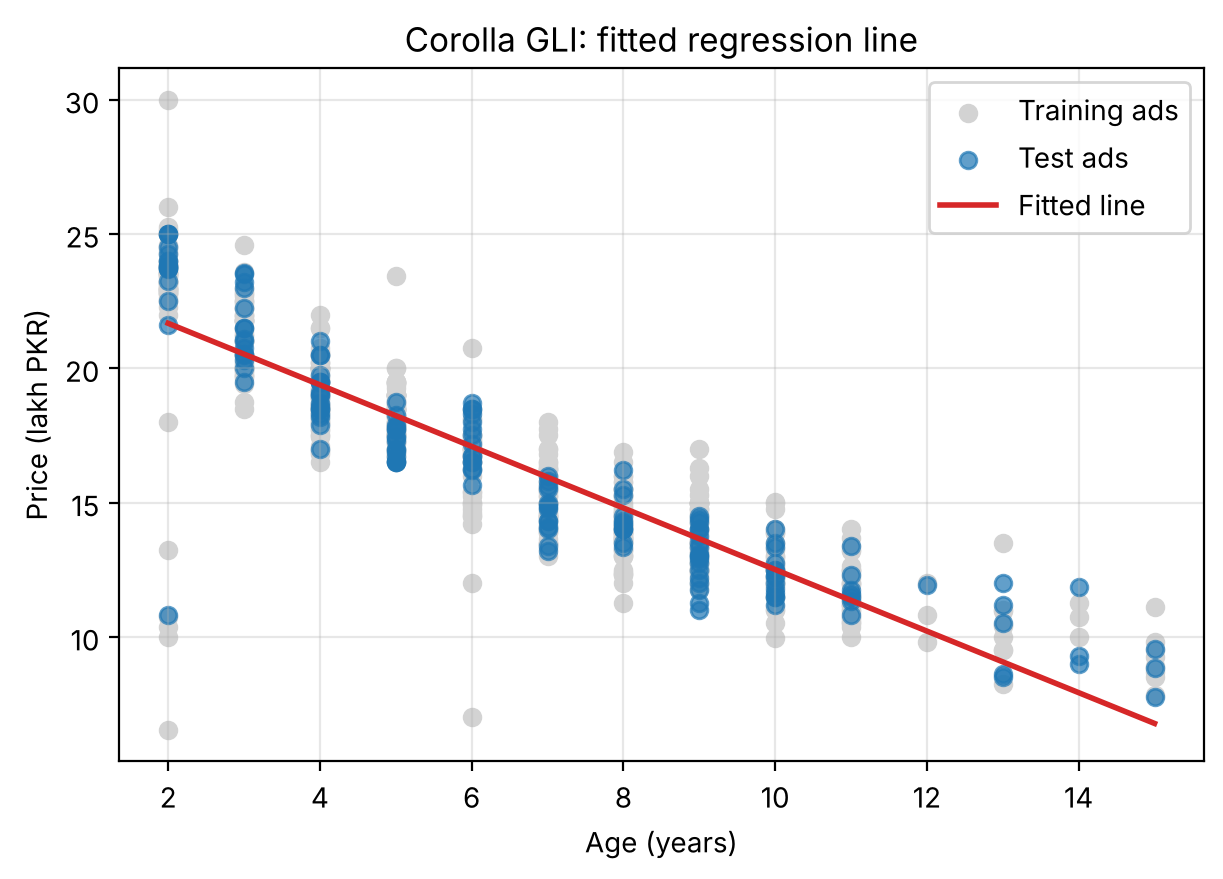

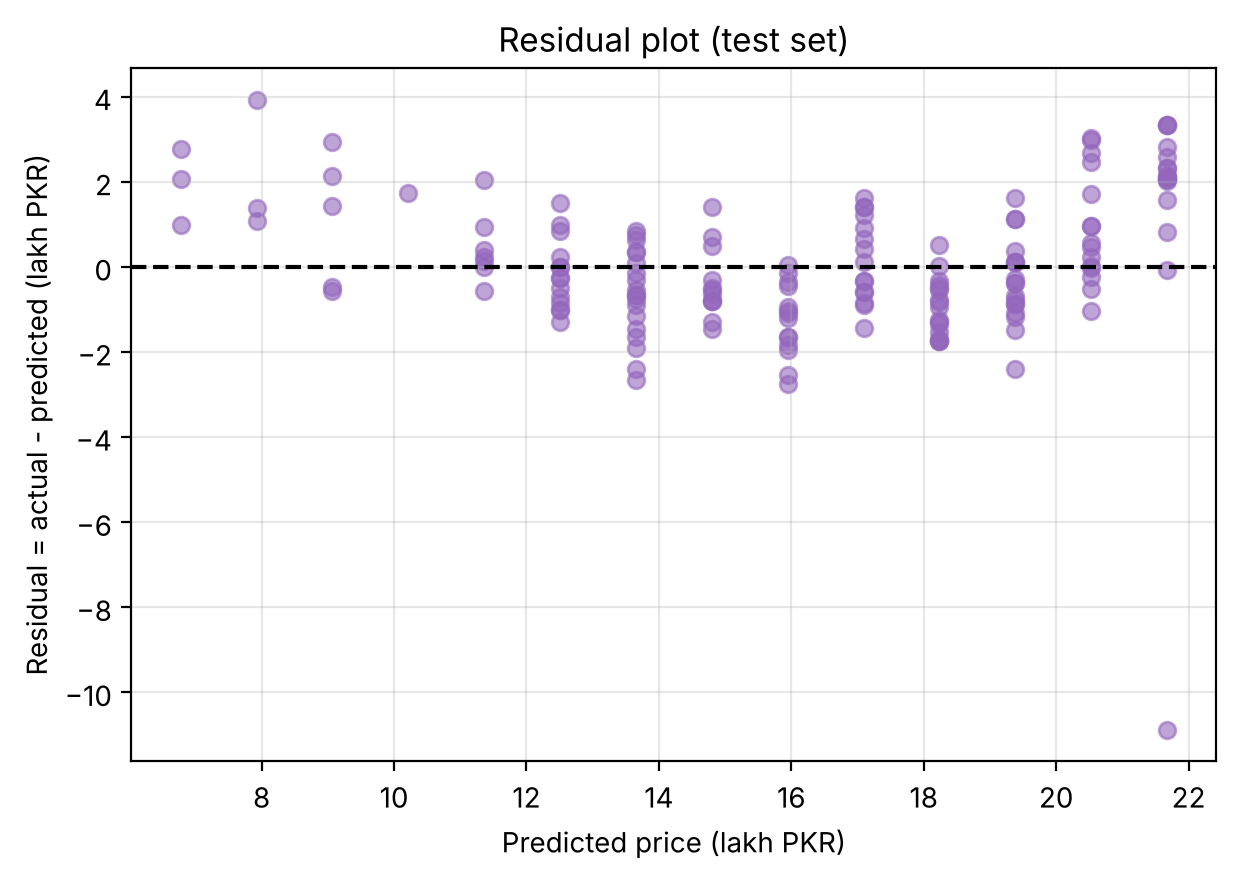

T6c: five largest errors on the test set
       Year  KMs Driven Registered City  Actual_lakh  Predicted_lakh  Abs_error
18857  2018         NaN         Unknown        10.80           21.67      10.87
20280  2006    220000.0       Islamabad        11.85            7.92       3.93
17363  2018         NaN         Unknown        25.00           21.67       3.33
18980  2018         NaN         Unknown        25.00           21.67       3.33
16557  2018       300.0         Unknown        25.00           21.67       3.33


In [7]:
# T6: visualise
# (a) data + fitted line
line_x = pd.DataFrame({"Age": np.linspace(X["Age"].min(), X["Age"].max(), 100)})
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train["Age"], y_train, color="lightgrey", label="Training ads")
plt.scatter(X_test["Age"], y_test, color="tab:blue", alpha=0.7, label="Test ads")
plt.plot(line_x["Age"], model.predict(line_x), color="tab:red", linewidth=2,
         label="Fitted line")
plt.title("Corolla GLI: fitted regression line")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh PKR)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# (b) residual plot (test set)
residuals = yt - y_pred
plt.figure(figsize=(7, 4.5))
plt.scatter(y_pred, residuals, alpha=0.6, color="tab:purple")
plt.axhline(0, color="black", linestyle="--")
plt.title("Residual plot (test set)")
plt.xlabel("Predicted price (lakh PKR)")
plt.ylabel("Residual = actual - predicted (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()

# (c) five largest absolute errors
res = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
res["Actual_lakh"] = y_test
res["Predicted_lakh"] = y_pred
res["Abs_error"] = np.abs(res["Actual_lakh"] - res["Predicted_lakh"])
res = res.round(2)
print("T6c: five largest errors on the test set")
print(res.sort_values("Abs_error", ascending=False).head(5))

---

**Residual shape:** the residual plot is not a pure random cloud: it shows a mild curve (U-shape) and a mild funnel. Residuals are mostly positive for the newest cars (predicted ≈ 20–22 lakh), mostly negative in the middle (≈ 12–19 lakh) and positive again for the oldest cars (predicted below ≈ 10 lakh). This means real prices drop faster in the first years and flatten later, while a straight line falls at a constant rate. The spread is also larger at the highest predicted prices (residual standard deviation ≈ 2.2 lakh, against ≈ 1.0–1.3 lakh for the middle and lower prices), so expensive newer cars are harder to predict. Both effects are mild: the line still explains 84.5 % of the variation, and a curved (quadratic) model would be the natural next step.

**Largest errors:** most of them are mistakes in the data, not in the model. The largest is a 2018 Corolla GLI listed at 10.80 lakh with city “Unknown” and missing KMs Driven, while the model predicts 21.67 lakh: it is 10.87 lakh below similar cars, most likely a wrong price or a down payment typed as the price. Three more of the top five are 2018 ads priced exactly 25.00 lakh (a round asking price), again with missing KMs or city “Unknown”, or an implausible 300 km. Only the 2006 car (220,000 km, actual 11.85 vs predicted 7.92 lakh) is a model limitation: age alone cannot see its condition or equipment.

## Task 7 · Use the model


In [8]:
# T7: use the model
REF_YEAR = 2020           # the dataset defines Age = 2020 - Year
years = [2018, 2015, 2010]
new_cars = pd.DataFrame({"Age": [REF_YEAR - yr for yr in years]})
for yr, p in zip(years, model.predict(new_cars)):
    print(f"T7a: {yr} Corolla GLI (age {REF_YEAR - yr}) -> {p:.2f} lakh")

old_car = pd.DataFrame({"Age": [REF_YEAR - 1995]})
print("T7b: 1995 Corolla GLI (age 25) ->", round(model.predict(old_car)[0], 2), "lakh")
print("T7b: training ages range from", X["Age"].min(), "to", X["Age"].max())

T7a: 2018 Corolla GLI (age 2) -> 21.67 lakh
T7a: 2015 Corolla GLI (age 5) -> 18.24 lakh
T7a: 2010 Corolla GLI (age 10) -> 12.51 lakh
T7b: 1995 Corolla GLI (age 25) -> -4.68 lakh
T7b: training ages range from 2 to 15


---

**Answer:** No, (b) is not believable. The model predicts about −4.7 lakh rupees, a negative price, which is impossible. Age 25 is far outside the ages the model learned from (about 2–15 years), so this is extrapolation: the straight line keeps falling by 1.146 lakh every year, whereas real prices flatten out (a car never drops below its scrap or collector value). The predictions for 2018, 2015 and 2010 (≈ 21.7, 18.2 and 12.5 lakh) lie inside the data range and are reasonable.

## Task 8 · Reflection 

**Reflection:** I loaded the OLX data, filtered it to 796 Corolla GLI cash ads from 2005–2018 priced 5–40 lakh, checked the scatter plot and correlation (−0.896), set X = Age (2-D) and y = price, split 80/20 with random_state=42, found b₁ and b₀ by least squares in NumPy on the training data, confirmed them with scikit-learn, and then evaluated, plotted residuals and predicted new cars. The model is judged on the test set because the training ads were used to choose the line, so training scores look too good; only unseen ads show how it will behave on a real new listing. To a car buyer I would say the MAE: “the price estimate is typically off by about 1.2 lakh”, because it is in rupees and easy to understand, while R² (0.845) is a share of variation and is not accuracy. One limitation of using age alone is that it ignores mileage, city, condition and seller type, so two cars of the same age can have very different prices, and it fails outside ages 2–15 (negative prices).